In [3]:
%pip install kagglehub pandas seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


/Users/medilin/ironhack/projects/week_5/lab-eda-univariate/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

# Set the path to the file you'd like to load
file_path = "amz_uk_price_prediction_dataset.csv"

# Load the latest version
amazon_df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/uk-optimal-product-price-prediction",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)
amazon_df

/var/folders/9x/t81_t1w14_s8w2jy_nx_xn4m0000gn/T/ipykernel_61114/1117690635.py:5: DeprecationWarning: load_dataset is deprecated and will be removed in a future version.
  amazon_df = kagglehub.load_dataset(


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
frequency_table = amazon_df['category'].value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
top5_categories = amazon_df['category'].value_counts().head(5)
top5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

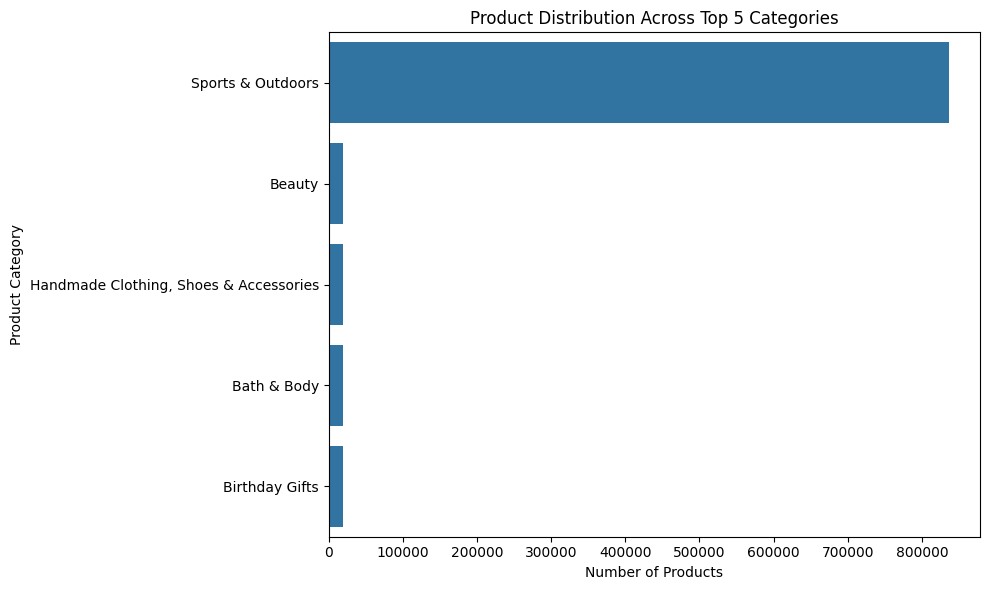

In [6]:

# Calculate top 5 categories
top5_categories = amazon_df['category'].value_counts().head(5)
top5_category_names = top5_categories.index.tolist()

# Filter data for only top 5 categories
df_top5 = amazon_df[amazon_df['category'].isin(top5_category_names)]

# Count frequency per category
category_counts = df_top5['category'].value_counts().sort_values(ascending=False)

# Bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index,)
plt.title('Product Distribution Across Top 5 Categories')
plt.xlabel('Number of Products')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()


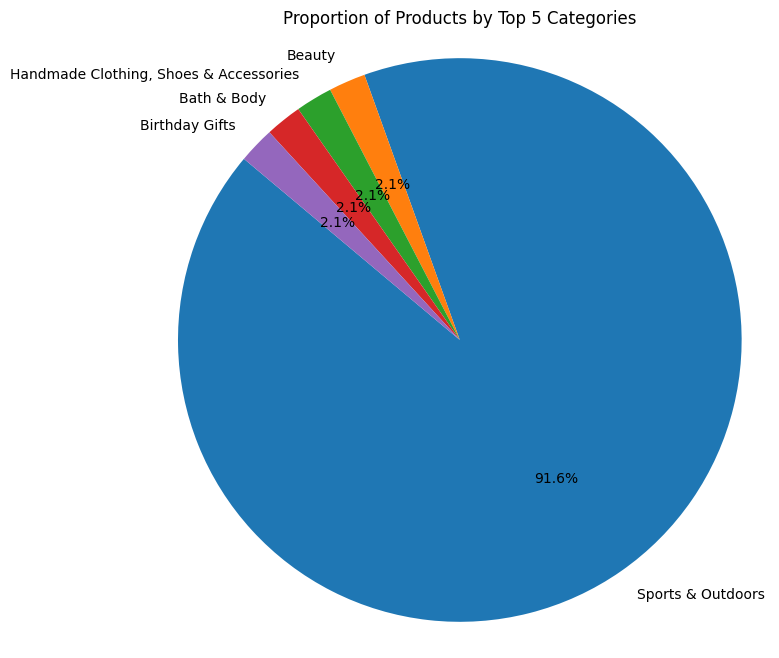

In [7]:


# Calculate counts for top 5 categories
top5_categories = amazon_df['category'].value_counts().head(5)

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(top5_categories.values, labels=top5_categories.index, autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Products by Top 5 Categories')
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle.
plt.show()


In [13]:
mean_price= amazon_df['price'].mean()
mean_price

np.float64(89.24380943923661)

In [14]:
median_price = amazon_df['price'].median()
median_price

np.float64(19.09)

In [15]:
mode_price = amazon_df['price'].mode()
mode_price

0    9.99
Name: price, dtype: float64

In [18]:
mean_price = amazon_df['price'].mean()
mode_price = amazon_df['price'].mode()

print(f'Average price:{mean_price}')
print(f'Most common price:{mode_price.values}')

Average price:89.24380943923661
Most common price:[9.99]


1) the average price of products listed is 89$ and the most common price point is about 10$.
That means there is a huge difference between prices (price variation)

In [5]:

# Calculate variance
price_variance = amazon_df['price'].var()

# Calculate standard deviation 
price_std = amazon_df['price'].std()

# Calculate range
price_range = amazon_df['price'].max() - amazon_df['price'].min()

# Calculate interquartile range
Q1 = amazon_df['price'].quantile(0.25)
Q3 = amazon_df['price'].quantile(0.75)
price_iqr = Q3 - Q1

print(f'Variance: {price_variance}')
print(f'Standard Deviation: {price_std}')
print(f'Range (max price - min price): {price_range}')
print(f'Interquartile Range (quantile 3 - quantile 1): {price_iqr}')

Variance: 119445.48532254901
Standard Deviation: 345.60886175349873
Range (max price - min price): 100000.0
Interquartile Range (quantile 3 - quantile 1): 36.0


2) the difference between range and interquartile price range are meaningful: the prices are spread widely.

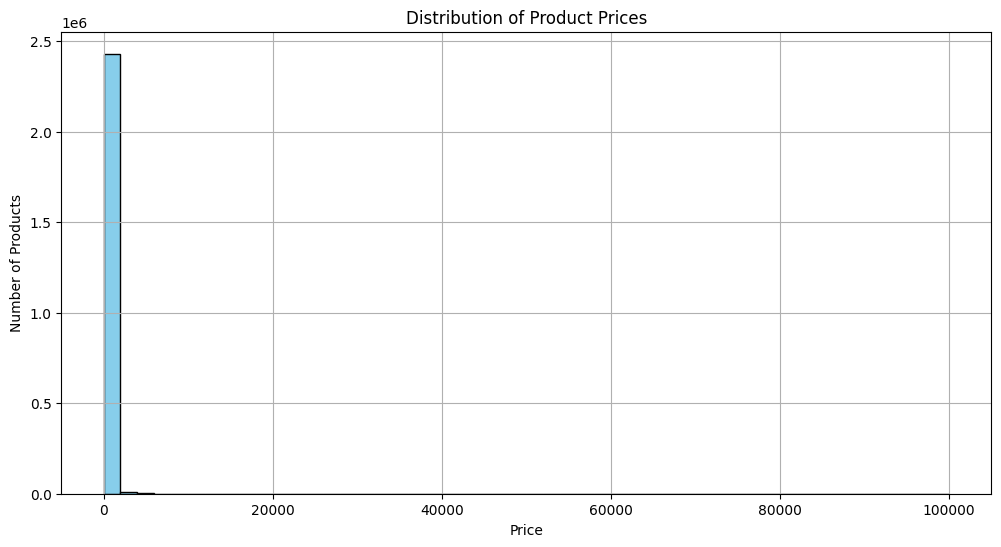

In [19]:


plt.figure(figsize=(12, 6))
plt.hist(amazon_df['price'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Number of Products')
plt.grid(True)
plt.show()


The price distribution is heavily skewed so there is many products at low prices and a few expensive outliers, the histogram bars for the lower prices could be very tall and compress the detail for higher price ranges.

A few very high priced products create a long tail that stretches the x-axis, making the majority of data clustered to one side and hard to interpret.



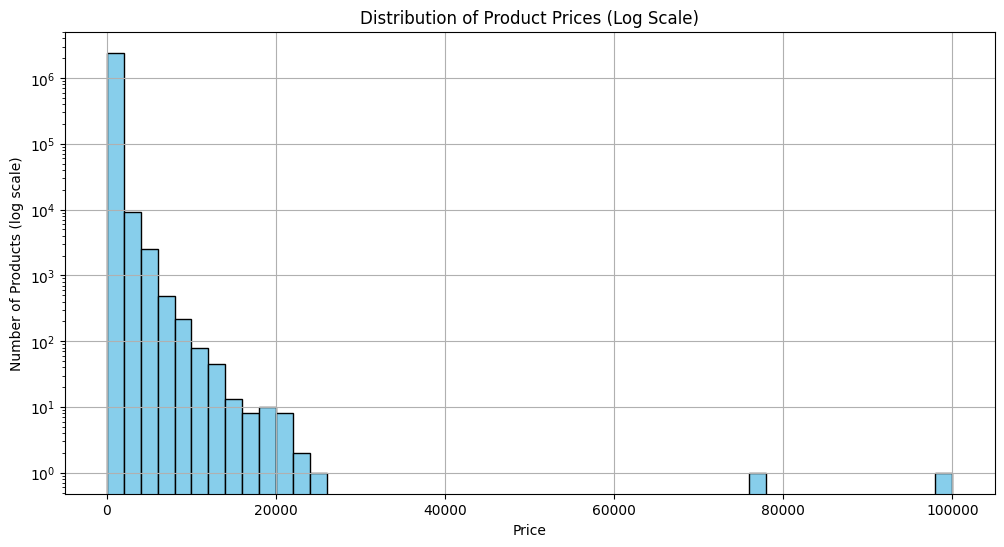

In [21]:
#use logarithmic scaling on the price axis to spread out the data more evenly:
plt.figure(figsize=(12, 6))
plt.hist(amazon_df['price'], bins=50, color='skyblue', edgecolor='black', log=True)
plt.title('Distribution of Product Prices (Log Scale)')
plt.xlabel('Price')
plt.ylabel('Number of Products (log scale)')
plt.grid(True)
plt.show()


# part 3

In [14]:

# Calculate mean, median and mode of stars column
mean_stars = amazon_df['stars'].mean()
median_stars = amazon_df['stars'].median()
mode_stars = amazon_df['stars'].mode()[0]
print(f'Mean stars: {round(mean_stars, 2)}')
print(f'Median stars: {median_stars}')
print(f'Mode stars: {mode_stars}')

Mean stars: 2.15
Median stars: 0.0
Mode stars: 0.0


1) Customer's trend is to rate 0 most of the products.

In [17]:

# Calculate variance
variance = amazon_df['stars'].var()

# Calculate standard deviation 
std_dev = amazon_df['stars'].std()

# Calculate interquartile range
q75 = amazon_df['stars'].quantile(0.75)
q25 = amazon_df['stars'].quantile(0.25)
iqr = q75 - q25

print(f'range: {amazon_df['stars'].max() - amazon_df['stars'].min()}')
print(f'Variance: {round(variance,2)}')
print(f'Standard Deviation: {round(std_dev,2)}')
print(f'Interquartile Range: {iqr}')

range: 5.0
Variance: 4.82
Standard Deviation: 2.19
Interquartile Range: 4.4


2) very wide variation in customer ratings rather than consistency.

In [19]:

# Calculate skewness and kurtosis for ratings
skewness = amazon_df['stars'].skew()
kurtosis = amazon_df['stars'].kurtosis()

print(f'Skewness: {skewness}')
print(f'Kurtosis: {kurtosis}')

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


3) The ratings are effectively normally distributed with virtually no lean toward higher or lower values (skewness ≈ +0.08), but they have lighter tails than a normal curve (kurtosis ≈ –1.93), meaning few extreme outliers.

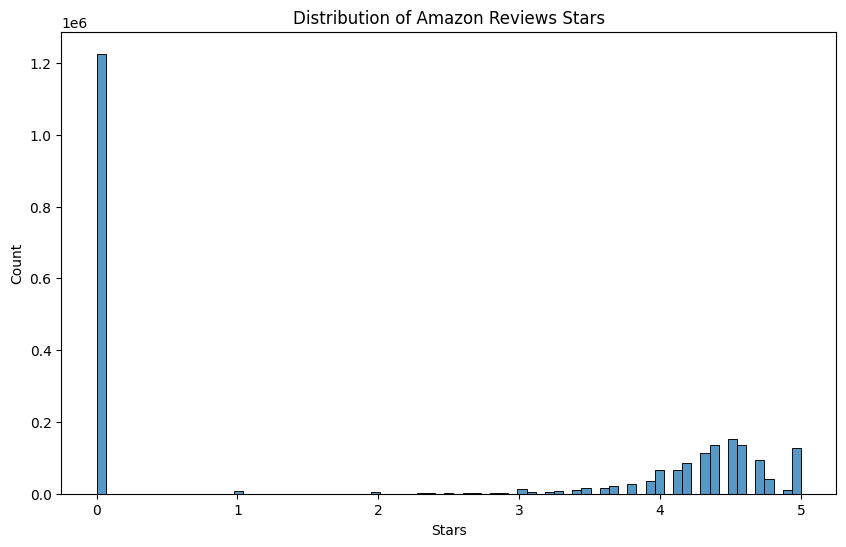

In [21]:

# Create histogram using seaborn
plt.figure(figsize=(10,6))
sns.histplot(data=amazon_df, x='stars')

# Customize plot
plt.title('Distribution of Amazon Reviews Stars')
plt.xlabel('Stars')
plt.ylabel('Count')

# Display plot
plt.show()

4) 0 rating is dominating